<a href="https://colab.research.google.com/github/AzureYue/data-science-toolkit/blob/main/Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
df = pd.read_csv("covid_19_indonesia_time_series_all.csv")

 My problem statement is "The region mostly affected by Covid 19 in Indonesia"

2. Evaluate if the data is good or not. Does it have enough samples?


In [ ]:
#Check duplicates duplicates
duplicates = df.duplicated().sum()
print("\n## Number of duplicates: ", duplicates)

shape = df.shape
print("\n## Shape of dataset: ",shape)

missing_values = df.isnull().sum()
print("\n## Missing values:\n ", missing_values)

unique = df['Total Cases per Million'].nunique()
print("\n## Unique number of Total Cases per Million: ", unique)

preview = df.head()
print("\n## Preview of dataset: \n", preview)



## Number of duplicates:  0

## Shape of dataset:  (31822, 38)

## Missing values:
  Date                               0
Location ISO Code                  0
Location                           0
New Cases                          0
New Deaths                         0
New Recovered                      0
New Active Cases                   0
Total Cases                        0
Total Deaths                       0
Total Recovered                    0
Total Active Cases                 0
Location Level                     0
City or Regency                31822
Province                         929
Country                            0
Continent                          0
Island                           929
Time Zone                        929
Special Status                 27264
Total Regencies                    0
Total Cities                     901
Total Districts                    0
Total Urban Villages             904
Total Rural Villages             929
Area (km2)                

Answer: The dataset has clean and structured data with 31822 non-duplicate samples. While it has some missing values on a few features, it does not affect the key findings of this dataset. Overall, the data is good enough.

3. How many features does it have? Is it enough?

In [ ]:
cols = df.columns.tolist()
print("Columns: ")
print(cols)

num_of_features = len(rows)-1
print("\nNumber of features: ", num_of_features)

Columns: 
['Date', 'Location ISO Code', 'Location', 'New Cases', 'New Deaths', 'New Recovered', 'New Active Cases', 'Total Cases', 'Total Deaths', 'Total Recovered', 'Total Active Cases', 'Location Level', 'City or Regency', 'Province', 'Country', 'Continent', 'Island', 'Time Zone', 'Special Status', 'Total Regencies', 'Total Cities', 'Total Districts', 'Total Urban Villages', 'Total Rural Villages', 'Area (km2)', 'Population', 'Population Density', 'Longitude', 'Latitude', 'New Cases per Million', 'Total Cases per Million', 'New Deaths per Million', 'Total Deaths per Million', 'Total Deaths per 100rb', 'Case Fatality Rate', 'Case Recovered Rate', 'Growth Factor of New Cases', 'Growth Factor of New Deaths']

Number of features:  37


Answer: Yes, the dataset has enough features. It has **37** features excluding the target column.

4. How many samples/observation does it have? Is it enough?

In [ ]:
rows = len(df)
print("Number of samples: ", rows)

Number of samples:  31822


Answer: Yes, the dataset has enough samples. It has **31882** samples.

5. What are the datatypes does the dataset consist of?


In [ ]:
print(df.dtypes)

Date                            object
Location ISO Code               object
Location                        object
New Cases                        int64
New Deaths                       int64
New Recovered                    int64
New Active Cases                 int64
Total Cases                      int64
Total Deaths                     int64
Total Recovered                  int64
Total Active Cases               int64
Location Level                  object
City or Regency                float64
Province                        object
Country                         object
Continent                       object
Island                          object
Time Zone                       object
Special Status                  object
Total Regencies                  int64
Total Cities                   float64
Total Districts                  int64
Total Urban Villages           float64
Total Rural Villages           float64
Area (km2)                       int64
Population               

Answer: The dataset consists of **text** ("object"), **integers** ("int64") and decimal **numbers** ("float64")

6. How many columns have null values? If yes, which column, which rows

In [ ]:
cols_with_missing = df.isnull().sum()[(df.isnull().any())]
print("\n## Columns with missing values: \n",cols_with_missing)

cols_with_missing_list = df.isnull().sum()[(df.isnull().any())].index.tolist()
#print("\n## Columns with missing values: \n",cols_with_missing_list)

cols_with_missing_num = df.isnull().any().sum()
print("\n## Total number of columns with null values: \n",cols_with_missing_num)

cells_with_missing = df.isnull().sum().sum()
print("\n## Total number of cells with missing values: \n",cells_with_missing)



## Columns with missing values: 
 City or Regency                31822
Province                         929
Island                           929
Time Zone                        929
Special Status                 27264
Total Cities                     901
Total Urban Villages             904
Total Rural Villages             929
Growth Factor of New Cases      1939
Growth Factor of New Deaths     3447
dtype: int64

## Total number of columns with null values: 
 10

## Total number of cells with missing values: 
 69993


In [ ]:
#Rows with missing values
rows=df[df.isnull().any(axis=1)]
print("## Preview of rows with null values: \n",rows.head())
print("\n## Number of rows with null values: ",len(rows))

# Preview rows where 'Growth Factor of New Cases' specifically is missing
print("\n## Rows with missing 'Growth Factor of New Cases':")
display(df[df['Growth Factor of New Cases'].isnull()].head())


## Preview of rows with null values: 
        Date Location ISO Code     Location  New Cases  New Deaths  \
0  3/1/2020             ID-JK  DKI Jakarta          2           0   
1  3/2/2020             ID-JK  DKI Jakarta          2           0   
2  3/2/2020               IDN    Indonesia          2           0   
3  3/2/2020             ID-RI         Riau          1           0   
4  3/3/2020             ID-JK  DKI Jakarta          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2           39            20   
1              0                 2           41            20   
2              0                 2            2             0   
3              0                 1            1             0   
4              0                 2           43            20   

   Total Recovered  ...  Latitude New Cases per Million  \
0               75  ... -6.204699                  0.18   
1               75  ... -6.204699    

,Date,Location ISO Code,Location,New Cases,New Deaths,New Recovered,New Active Cases,Total Cases,Total Deaths,Total Recovered,...,Latitude,New Cases per Million,Total Cases per Million,New Deaths per Million,Total Deaths per Million,Total Deaths per 100rb,Case Fatality Rate,Case Recovered Rate,Growth Factor of New Cases,Growth Factor of New Deaths
0,3/1/2020,ID-JK,DKI Jakarta,2,0,0,2,39,20,75,...,-6.204699,0.18,3.60,0.00,1.84,0.18,51.28%,192.31%,NaN,NaN
2,3/2/2020,IDN,Indonesia,2,0,0,2,2,0,0,...,-0.789275,0.01,0.01,0.00,0.00,0.00,0.00%,0.00%,NaN,NaN
3,3/2/2020,ID-RI,Riau,1,0,0,1,1,0,1,...,0.511648,0.16,0.16,0.00,0.00,0.00,0.00%,100.00%,NaN,NaN
6,3/3/2020,ID-JB,Jawa Barat,1,1,0,0,1,1,60,...,-6.920432,0.02,0.02,0.02,0.02,0.00,100.00%,6000.00%,NaN,NaN
16,3/6/2020,ID-BT,Banten,1,0,1,0,1,5,111,...,-6.456736,0.09,0.09,0.00,0.47,0.05,500.00%,11100.00%,NaN,NaN


Answer: 10 columns have null values. That is  
"City or Regency"                
"Province"                      
"Island"                           
"Time Zone"                       
"Special Status"              
"Total Cities"                
"Total Urban Villages"       
"Total Rural Villages"   
"Growth Factor of New Cases"                  
"Growth Factor of New Deaths"   


7. Which are are features and which is the target?

In [ ]:
features= df.drop(columns=["Total Cases per Million"])
target = df["Total Cases per Million"]
print("## Features: \n", features.columns.tolist())
print("\n## Target: ", target.name)

## Features: 
 ['Date', 'Location ISO Code', 'Location', 'New Cases', 'New Deaths', 'New Recovered', 'New Active Cases', 'Total Cases', 'Total Deaths', 'Total Recovered', 'Total Active Cases', 'Location Level', 'City or Regency', 'Province', 'Country', 'Continent', 'Island', 'Time Zone', 'Special Status', 'Total Regencies', 'Total Cities', 'Total Districts', 'Total Urban Villages', 'Total Rural Villages', 'Area (km2)', 'Population', 'Population Density', 'Longitude', 'Latitude', 'New Cases per Million', 'New Deaths per Million', 'Total Deaths per Million', 'Total Deaths per 100rb', 'Case Fatality Rate', 'Case Recovered Rate', 'Growth Factor of New Cases', 'Growth Factor of New Deaths']

## Target:  Total Cases per Million


8. Does it have missing values? If yes, which column, which row.

In [ ]:
# Display the columns that are True (have null values)
nulls = df.isnull().any()
display(any_nulls[any_nulls])

missing_values = df.isnull().sum()
print("\nColumns with Missing values:\n ", missing_values[missing_values>0])

# Preview rows where 'Growth Factor of New Cases' specifically is missing
print("\n## Rows with missing 'Growth Factor of New Cases':")
display(df[df['Growth Factor of New Cases'].isnull()][['Date','Total Cases per Million','Growth Factor of New Cases']].head())


,0
City or Regency,True
Province,True
Island,True
Time Zone,True
Special Status,True
Total Cities,True
Total Urban Villages,True
Total Rural Villages,True
Growth Factor of New Cases,True
Growth Factor of New Deaths,True



Columns with Missing values:
  City or Regency                31822
Province                         929
Island                           929
Time Zone                        929
Special Status                 27264
Total Cities                     901
Total Urban Villages             904
Total Rural Villages             929
Growth Factor of New Cases      1939
Growth Factor of New Deaths     3447
dtype: int64

## Rows with missing 'Growth Factor of New Cases':


,Date,Total Cases per Million,Growth Factor of New Cases
0,3/1/2020,3.60,NaN
2,3/2/2020,0.01,NaN
3,3/2/2020,0.16,NaN
6,3/3/2020,0.02,NaN
16,3/6/2020,0.09,NaN


Answer: Yes, the dataset has missing values.

9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

Answer: Factors that affect the target, and relationships between the target and other features are significant.
Below shown are two examples:
1. Relationship between New Cases Per Million and Total Cases Per Million
2. Locations with the most Total Cases Per Million

Correlation between 'New Cases per Million' and 'Total Cases per Million': 0.2883



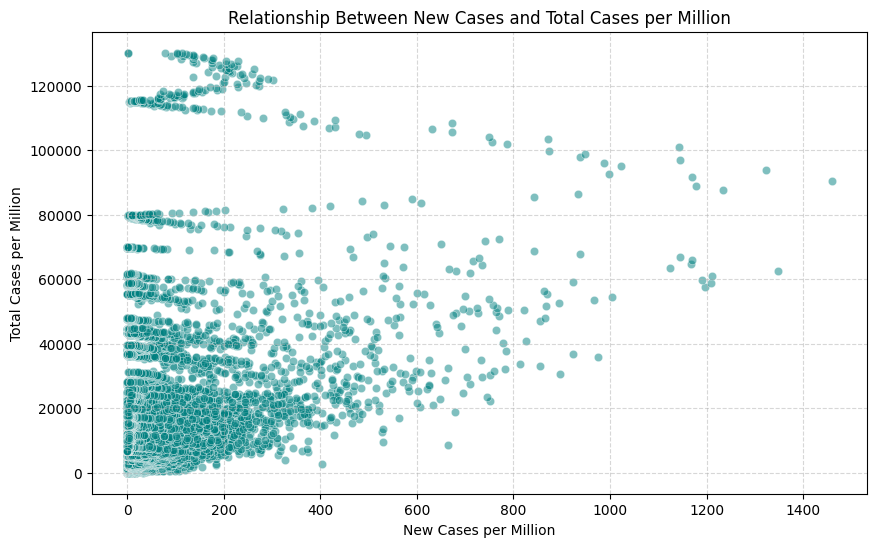

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Calculate the correlation coefficient between New Cases Per Mil and Total Cases Per Mil
correlation = df['New Cases per Million'].corr(df['Total Cases per Million'])
print(f"Correlation between 'New Cases per Million' and 'Total Cases per Million': {correlation:.4f}")
print()

# 2) Plot the relationship with a Scatterplot
# Scatterplot is used because
# both variables are continuous
# identifies density and outliers
# handles large dataset
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='New Cases per Million', y='Total Cases per Million', alpha=0.5, color='teal')
plt.title("Relationship Between New Cases and Total Cases per Million")
plt.xlabel("New Cases per Million")
plt.ylabel("Total Cases per Million")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

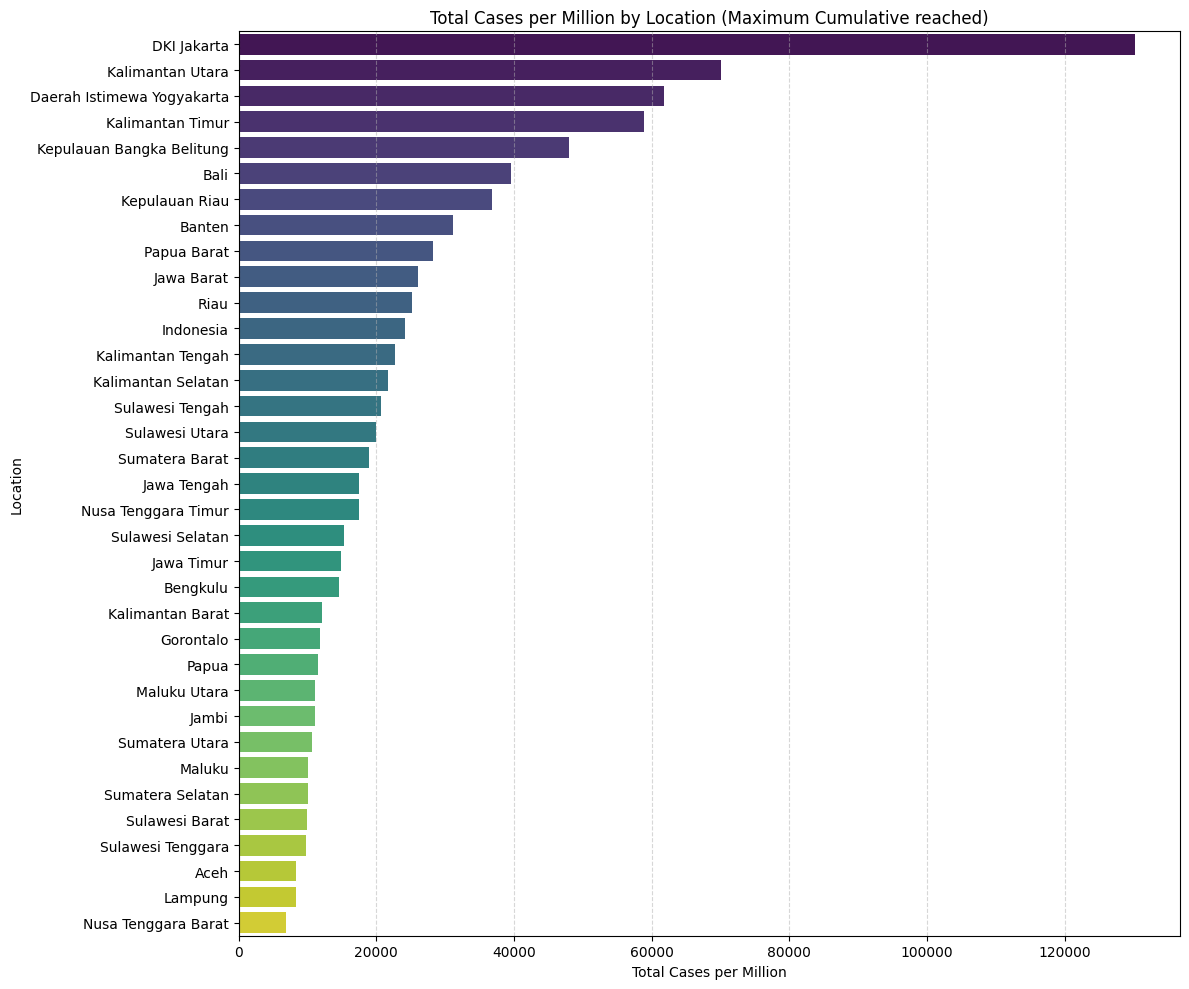

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Group by Location and find the maximum 'Total Cases per Million' reached
location_max_cases = df.groupby('Location')['Total Cases per Million'].max().reset_index()

# 2) Sort the values in descending order
location_max_cases = location_max_cases.sort_values(by='Total Cases per Million', ascending=False)

# 3) A bar chart to visualise the most affected region
plt.figure(figsize=(12, 10))
sns.barplot(
    data=location_max_cases,
    x='Total Cases per Million',
    y='Location',
    palette='viridis',
    hue='Location',
    legend=False
)

plt.title("Total Cases per Million by Location (Maximum Cumulative reached)")
plt.xlabel("Total Cases per Million")
plt.ylabel("Location")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# plt.grid()
# True: show grid lines, axis='x': apply gridlines only to the x-axis
# linestyle ='--' : solid -> dashed
# alpha=0.5: transparency of grid lines
# plt.tight_layout(): automatically adjust subplot parameters to prevent overlap of labels